In [5]:
import pandas as pd, numpy as np, joblib, time
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (adjusted_rand_score, silhouette_score, davies_bouldin_score, calinski_harabasz_score)
from sklearn.tree import DecisionTreeClassifier, export_text

P = Path("../data/processed")
if not P.exists(): P = Path("data/processed")

SEED = 42
K_BEST = 4

rfm_scaled = pd.read_parquet(P/"customer_rfm_scaled.parquet")
rfm_result = pd.read_parquet(P/"customer_rfm_clusters.parquet") # raw R/F/M + Cluster
X = rfm_scaled[["Recency", "Frequency", "Monetary"]].to_numpy()
N = len(X)

print("Clients :", N)
print("K_BEST =", K_BEST, " | SEED =", SEED)

Clients : 5877
K_BEST = 4  | SEED = 42


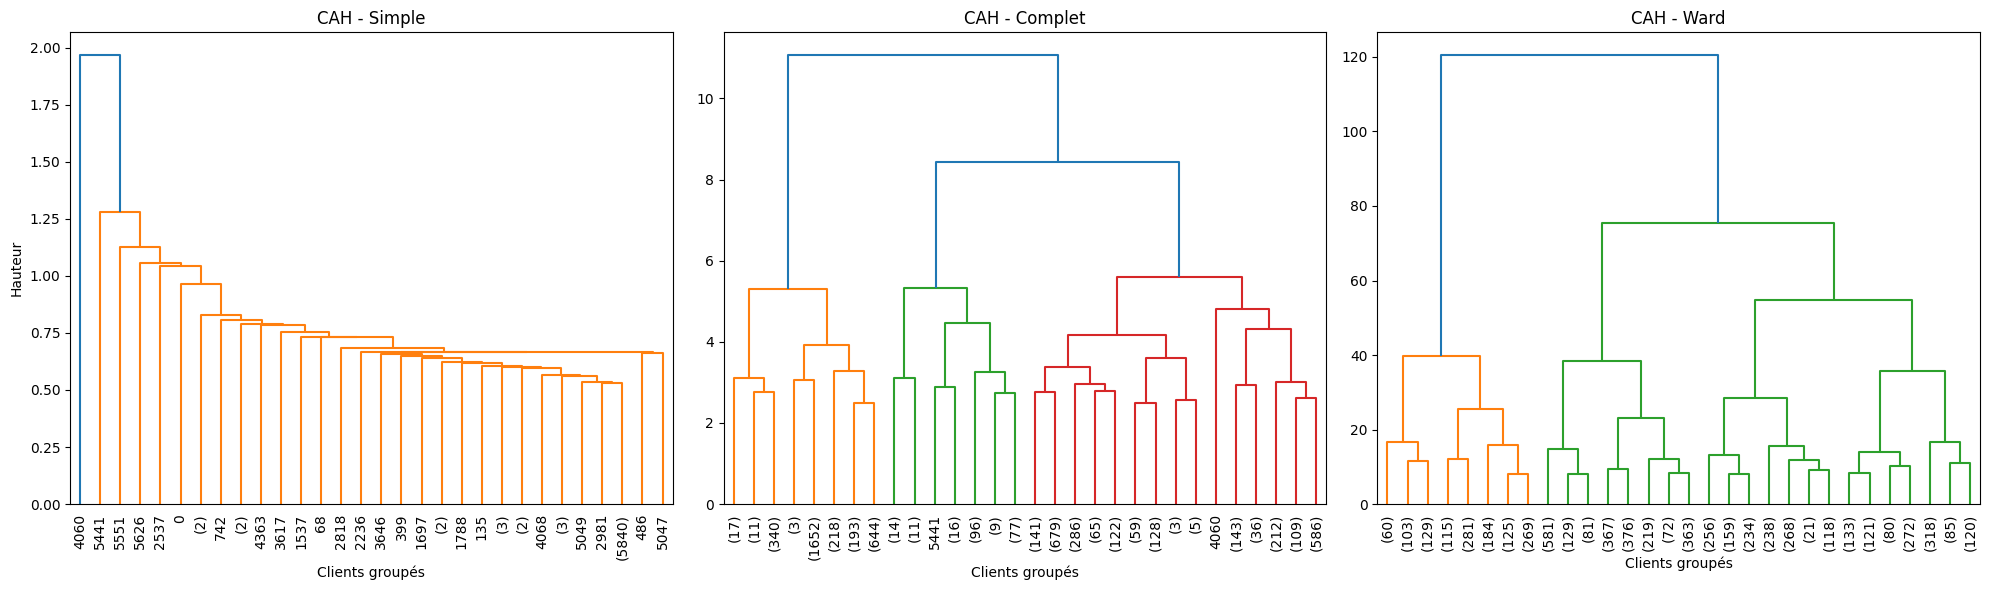

In [6]:
# Liens simple, complet et Ward 
Z_simple   = linkage(X, method="single")
Z_complete = linkage(X, method="complete")
Z_ward     = linkage(X, method="ward")

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, Z, name in zip(axes, [Z_simple, Z_complete, Z_ward], ["Simple", "Complet", "Ward"]):
    dendrogram(Z, ax=ax, truncate_mode="lastp", p=30, leaf_rotation=90)
    ax.set_title(f"CAH - {name}")
    ax.set_ylabel("Hauteur" if ax is axes[0] else "")
    ax.set_xlabel("Clients groupés")
plt.tight_layout()
plt.show()


In [7]:
# Coupure à K_BEST clusters (hauteur)
labels_ward = fcluster(Z_ward, t=K_BEST, criterion="maxclust")

# Profilage en valeurs BRUTES (ce que lit le marketing)
prof = (rfm_result.assign(Cluster_CAH=labels_ward).groupby("Cluster_CAH")[["Recency", "Frequency", "Monetary"]].agg(["mean", "median", "count"]))
print(prof)

                Recency               ...     Monetary                
                   mean median count  ...         mean    median count
Cluster_CAH                           ...                             
1             24.033175   16.0  1266  ...  9715.546213  4238.080  1266
2            424.988574  411.0  2188  ...   539.897300   363.195  2188
3            135.115147   91.0  1294  ...  2365.684427  1613.680  1294
4             42.302923   26.0  1129  ...   626.912118   439.430  1129

[4 rows x 9 columns]


In [ ]:
# --- ARI CAH vs K-Means ---
labels_km = rfm_result["Cluster"].to_numpy()

ari = adjusted_rand_score(labels_ward, labels_km)
print("ARI CAH vs K-Means =", round(ari, 3))

           mean    std    min    max
K-Means   0.982  0.021  0.899  0.994
CAH-Ward  0.493  0.079  0.395  0.687


In [9]:
rng = np.random.default_rng(SEED)
sub_size = min(20_000, N)
sub_idx = rng.choice(N, size=sub_size, replace=False)
Xsub = X[sub_idx]

t = time.time(); linkage(Xsub, method="ward"); t_cah = time.time() - t
t = time.time(); KMeans(n_clusters=K_BEST, n_init=10, random_state=SEED).fit_predict(X); t_km = time.time() - t
t = time.time(); KMeans(n_clusters= K_BEST, n_init=10, random_state=SEED).fit_predict(Xsub); t_km_sub = time.time() - t

print(f"CAH {sub_size:,}      : {t_cah:.1f}s")
print(f"K-Means full ({N:,}) : {t_km:.1f}s (linéaire en N)")
print(f"K-Means {sub_size:,}  : {t_km_sub:.1f}s")

# Hybride : CAH sur sous-échantillon -> centroïdes -> K-Means
agg = AgglomerativeClustering(n_clusters=K_BEST)
sub_lab = agg.fit_predict(Xsub)
centroids = np.array([Xsub[sub_lab == c].mean(axis=0) for c in range(K_BEST)])

hyb = KMeans(n_clusters=K_BEST, n_init=10, random_state=SEED, init=centroids).fit_predict(X)
print("Hybrid ARI vs K-Means =", round(adjusted_rand_score(hyb, labels_km), 3))

CAH 5,877      : 1.6s
K-Means full (5,877) : 3.3s (linéaire en N)
K-Means 5,877  : 0.4s
Hybrid ARI vs K-Means = 0.927


c:\Users\user\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\cluster\_kmeans.py:1410: RuntimeWarning: Explicit initial center position passed: performing only one init in KMeans instead of n_init=10.
  super()._check_params_vs_input(X, default_n_init=10)


In [16]:
def stability(B=20, frac=0.8, seed=SEED):
    rng_ = np.random.default_rng(seed)
    a_km, a_w = [], []
    for b in range(B):
        idx = rng_.choice(N, size=int(frac * N), replace=False)
        km_b = KMeans(n_clusters=K_BEST, n_init=10, random_state=b).fit(X[idx])
        a_km.append(adjusted_rand_score(labels_km[idx], km_b.labels_))
        w_b = fcluster(linkage(X[idx], method="ward"), t=K_BEST, criterion="maxclust")
        a_w.append(adjusted_rand_score(labels_ward[idx], w_b))
    return np.array(a_km), np.array(a_w)

stab_km, stab_w = stability()
print(pd.DataFrame({"K-Means": stab_km, "CAH-Ward": stab_w}).agg(["mean", "std", "min", "max"]).T.round(3))

           mean    std    min    max
K-Means   0.982  0.021  0.899  0.994
CAH-Ward  0.493  0.079  0.395  0.687


In [11]:
def sub_ari(seed):
    i = rng.choice(N, size=int(0.7 * N), replace=False)
    a = KMeans(n_clusters=K_BEST, n_init=10, random_state=seed).fit_predict(X[i])
    b = KMeans(n_clusters=K_BEST, n_init=10, random_state=seed + 1).fit_predict(X[i])
    return adjusted_rand_score(a, b)

aris = [sub_ari(s) for s in range(5)]
print("ARI sur 5 sous-échantillons :", [round(a, 3)for a in aris])
print("Moyenne ± std : ", round(np.mean(aris), 3), "±", round(np.std(aris), 3))

ARI sur 5 sous-échantillons : [0.997, 0.992, 0.995, 0.997, 0.989]
Moyenne ± std :  0.994 ± 0.003


In [12]:
# Démonstration du biais de la silhouette 
# Elle favorise les clusters compacts et sphériques → avantage K-Means
print("Silhouette K-Means :", round(silhouette_score(X, labels_km), 4))
print("Silhouette CAH-Ward :", round(silhouette_score(X, labels_ward), 4))

Silhouette K-Means : 0.3654
Silhouette CAH-Ward : 0.2818


In [13]:
decision = pd.DataFrame({
    "Critère"                : ["Volumétrie (N≈6k)", "Temps réel (nouveau client)", "Qualité des profils", "Coût calc"],
    "K-Means"                : ["Linéaire ✅", "Centroïde stocké → O(1) ✅", "Sphériques", "Faible"],
    "CAH"                    : ["Quadratique ❌", "Re-jeter toute la hiérarchie ❌", "Formes libres", "Élevé"],
})
print(decision)

                       Critère  ...                             CAH
0            Volumétrie (N≈6k)  ...                   Quadratique ❌
1  Temps réel (nouveau client)  ...  Re-jeter toute la hiérarchie ❌
2          Qualité des profils  ...                   Formes libres
3                    Coût calc  ...                           Élevé

[4 rows x 3 columns]


In [14]:
# --- CART : profilage descriptif (attention au raisonnement circulaire) ---
clf = DecisionTreeClassifier(max_depth=3, random_state=SEED)
clf.fit(X, labels_km)
print(export_text(clf, feature_names=["Recency_z", "Frequency_z","Monetary_z"]))

|--- Recency_z <= -0.17
|   |--- Frequency_z <= 0.57
|   |   |--- Monetary_z <= 0.58
|   |   |   |--- class: 2
|   |   |--- Monetary_z >  0.58
|   |   |   |--- class: 0
|   |--- Frequency_z >  0.57
|   |   |--- Monetary_z <= 0.33
|   |   |   |--- class: 2
|   |   |--- Monetary_z >  0.33
|   |   |   |--- class: 0
|--- Recency_z >  -0.17
|   |--- Monetary_z <= -0.25
|   |   |--- Frequency_z <= -0.06
|   |   |   |--- class: 1
|   |   |--- Frequency_z >  -0.06
|   |   |   |--- class: 3
|   |--- Monetary_z >  -0.25
|   |   |--- Frequency_z <= -0.38
|   |   |   |--- class: 1
|   |   |--- Frequency_z >  -0.38
|   |   |   |--- class: 3

